# Projeto Integrado — Telemetria de Jogos
### Análise Multidimensional de Dados (OLAP)

Este notebook utiliza Python e Pandas para realizar análises OLAP sobre os dados de telemetria de jogos, previamente tratados pelo processo de ETL.

In [29]:
import pandas as pd
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from google.colab import drive
from ipywidgets import interact, widgets

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
CSV_PATH = '/content/drive/MyDrive/PI_telemetria_de_jogos/'
DW_PATH = ':memory:'

# Carregamento dos Dados

Os dados utilizados foram tratados anteriormente pelo pipeline ETL.

Serão carregadas as tabelas de jogadores, sessões, partidas, compras, itens e itens comprados, permitindo análises de diferentes áreas do jogo.

In [36]:
jogadores = pd.read_csv(CSV_PATH + 'jogadores_limpo.csv')
sessoes = pd.read_csv(CSV_PATH + 'sessoes_limpo.csv')
partidas = pd.read_csv(CSV_PATH + 'partidas_limpo.csv')
compras = pd.read_csv(CSV_PATH + 'compras_limpo.csv')
itens = pd.read_csv(CSV_PATH + 'itens_limpo.csv')
itens_compras = pd.read_csv(CSV_PATH + 'itens_compras_limpo.csv')

resumo = pd.DataFrame({
    'Tabela': [
        'Jogadores', 'Sessões', 'Partidas',
        'Compras', 'Itens', 'Itens Comprados'
    ],
    'Registros': [
        len(jogadores), len(sessoes), len(partidas),
        len(compras), len(itens), len(itens_compras)
    ]
})

display(resumo)

,Tabela,Registros
0,Jogadores,1000
1,Sessões,37366
2,Partidas,58312
3,Compras,1425
4,Itens,37
5,Itens Comprados,1963


# Preparação das Consultas OLAP

Os arquivos já estão limpos. Nesta etapa, serão criadas apenas as referências de ano e mês necessárias para as consultas temporais.

In [37]:
sessoes['data_inicio_sessao'] = pd.to_datetime(
    sessoes['data_inicio_sessao']
)

sessoes['ano'] = sessoes['data_inicio_sessao'].dt.year
sessoes['mes'] = sessoes['data_inicio_sessao'].dt.month

conn = sqlite3.connect(':memory:')

jogadores.to_sql('jogadores', conn, if_exists='replace', index=False)
sessoes.to_sql('sessoes', conn, if_exists='replace', index=False)
partidas.to_sql('partidas', conn, if_exists='replace', index=False)
compras.to_sql('compras', conn, if_exists='replace', index=False)
itens.to_sql('itens', conn, if_exists='replace', index=False)
itens_compras.to_sql('itens_compras', conn, if_exists='replace', index=False)

print('Tabelas disponíveis para consultas OLAP.')

Tabelas disponíveis para consultas OLAP.


# Consultas OLAP — Engajamento

A análise de engajamento permite identificar quais plataformas e gêneros concentram mais atividade.

Serão utilizados indicadores de sessões, jogadores ativos, tempo médio e horas jogadas.

,plataforma,total_sessoes,jogadores_ativos,tempo_medio,horas_jogadas
0,PC,15355,689,101.85,26064.02
1,Xbox,10686,419,97.13,17298.03
2,PlayStation,9979,396,100.38,16694.28
3,Mobile,1346,222,89.64,2010.88


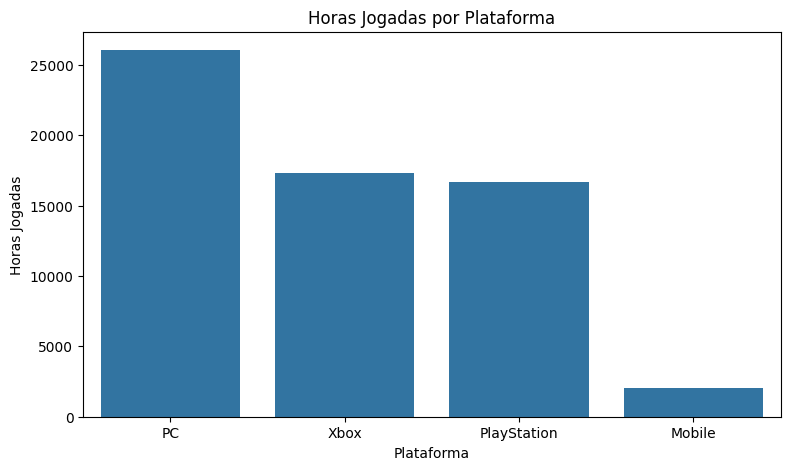

In [38]:
engajamento = pd.read_sql_query("""
    SELECT
        plataforma,
        COUNT(sessao_id) AS total_sessoes,
        COUNT(DISTINCT player_id) AS jogadores_ativos,
        ROUND(AVG(duracao_minutos), 2) AS tempo_medio,
        ROUND(SUM(duracao_minutos) / 60.0, 2) AS horas_jogadas
    FROM sessoes
    GROUP BY plataforma
    ORDER BY horas_jogadas DESC
""", conn)

display(engajamento)

plt.figure(figsize=(9, 5))
sns.barplot(data=engajamento, x='plataforma', y='horas_jogadas')
plt.title('Horas Jogadas por Plataforma')
plt.xlabel('Plataforma')
plt.ylabel('Horas Jogadas')
plt.show()

,genero_jogo,total_sessoes,jogadores_ativos,tempo_medio,horas_jogadas
0,Survival,3202,342,166.48,8884.48
1,Simulação,3040,315,151.08,7654.57
2,RPG,2965,323,150.08,7416.65
3,Estratégia,3836,329,110.18,7043.87
4,Aventura,3168,331,110.67,5843.62
5,FPS,4516,372,69.71,5246.57
6,Ação,3397,340,89.99,5094.93
7,MOBA,3043,313,88.68,4497.57
8,Esportes,3565,337,70.19,4170.18
9,Corrida,3409,341,59.63,3387.95


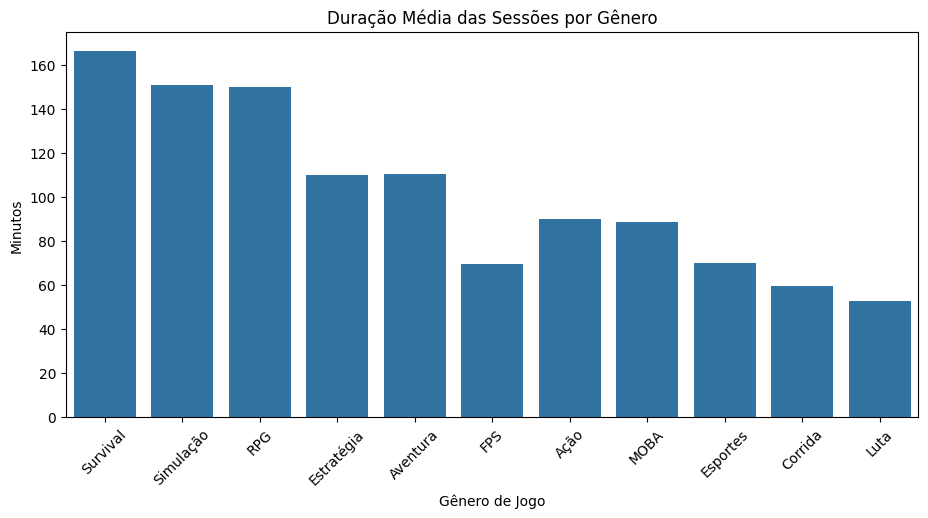

In [39]:
generos = pd.read_sql_query("""
    SELECT
        genero_jogo,
        COUNT(sessao_id) AS total_sessoes,
        COUNT(DISTINCT player_id) AS jogadores_ativos,
        ROUND(AVG(duracao_minutos), 2) AS tempo_medio,
        ROUND(SUM(duracao_minutos) / 60.0, 2) AS horas_jogadas
    FROM sessoes
    GROUP BY genero_jogo
    ORDER BY horas_jogadas DESC
""", conn)

display(generos)

plt.figure(figsize=(11, 5))
sns.barplot(data=generos, x='genero_jogo', y='tempo_medio')
plt.title('Duração Média das Sessões por Gênero')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Minutos')
plt.xticks(rotation=45)
plt.show()

# Cubo OLAP Tridimensional

O cubo permite visualizar simultaneamente as dimensões plataforma, gênero de jogo e ano.

O tamanho das esferas representa a quantidade de sessões, enquanto a cor indica a duração média.


In [40]:
cubo_olap = sessoes.groupby(
    ['ano', 'mes', 'plataforma', 'genero_jogo']
).agg(
    total_sessoes=('sessao_id', 'count'),
    tempo_total=('duracao_minutos', 'sum')
).reset_index()

cubo_olap['tempo_medio'] = (
    cubo_olap['tempo_total'] / cubo_olap['total_sessoes']
)

display(cubo_olap.head(10))

,ano,mes,plataforma,genero_jogo,total_sessoes,tempo_total,tempo_medio
0,2010,4,Xbox,Esportes,1,90,90.0
1,2010,4,Xbox,RPG,1,71,71.0
2,2010,6,PC,Simulação,1,238,238.0
3,2010,6,Xbox,Esportes,1,31,31.0
4,2010,7,Xbox,Ação,1,31,31.0
5,2010,7,Xbox,Corrida,1,58,58.0
6,2010,7,Xbox,Esportes,2,58,29.0
7,2010,8,Xbox,Esportes,1,116,116.0
8,2010,8,Xbox,RPG,1,96,96.0
9,2010,8,Xbox,Simulação,1,129,129.0


In [41]:
cubo_3d = cubo_olap.groupby(
    ['plataforma', 'genero_jogo', 'ano']
).agg(
    total_sessoes=('total_sessoes', 'sum'),
    tempo_total=('tempo_total', 'sum')
).reset_index()

cubo_3d['tempo_medio'] = (
    cubo_3d['tempo_total'] / cubo_3d['total_sessoes']
)

fig = px.scatter_3d(
    cubo_3d,
    x='plataforma',
    y='genero_jogo',
    z='ano',
    size='total_sessoes',
    color='tempo_medio',
    hover_data=['total_sessoes', 'tempo_total'],
    title='Cubo OLAP — Plataforma x Gênero x Ano',
    labels={
        'plataforma': 'Plataforma',
        'genero_jogo': 'Gênero de Jogo',
        'ano': 'Ano',
        'tempo_medio': 'Duração Média (min)',
        'total_sessoes': 'Sessões'
    }
)

fig.update_layout(height=700)
fig.show()

# Interface OLAP Interativa

A interface permite selecionar dimensões e indicadores para executar consultas SQL.

É possível analisar sessões, jogadores ativos e tempo de jogo por plataforma, gênero, período, estado e nível do jogador.

In [42]:
olap_dimensoes = {
    'Plataforma': 's.plataforma',
    'Gênero de Jogo': 's.genero_jogo',
    'Ano': 's.ano',
    'Mês': 's.mes',
    'Estado': 'j.estado',
    'Nível do Jogador': 'j.nivel_jogador'
}

olap_medidas = {
    'Quantidade de Sessões': 'COUNT(s.sessao_id)',
    'Jogadores Ativos': 'COUNT(DISTINCT s.player_id)',
    'Tempo Médio de Jogo': 'AVG(s.duracao_minutos)',
    'Horas Jogadas': 'SUM(s.duracao_minutos) / 60.0'
}

def consulta_interativa(dim1, dim2, indicador):

    if dim1 == dim2:
        print('Selecione dimensões diferentes.')
        return

    col1 = olap_dimensoes[dim1]
    col2 = olap_dimensoes[dim2] if dim2 != 'Nenhuma' else None

    dimensoes = f'{col1} AS dim1'
    agrupamento = 'dim1'

    if col2:
        dimensoes += f', {col2} AS dim2'
        agrupamento += ', dim2'

    query = f"""
        SELECT
            {dimensoes},
            ROUND({olap_medidas[indicador]}, 2) AS valor
        FROM sessoes s
        LEFT JOIN jogadores j
            ON s.player_id = j.player_id
        GROUP BY {agrupamento}
        ORDER BY valor DESC
    """

    resultado = pd.read_sql_query(query, conn)

    display(resultado)

    plt.figure(figsize=(11, 5))

    if col2:
        sns.barplot(
            data=resultado,
            x='dim1',
            y='valor',
            hue='dim2'
        )
        plt.legend(
            title=dim2,
            bbox_to_anchor=(1.05, 1),
            loc='upper left'
        )
    else:
        sns.barplot(
            data=resultado,
            x='dim1',
            y='valor'
        )

    plt.title(f'{indicador} por {dim1}')
    plt.xlabel(dim1)
    plt.ylabel(indicador)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

interact(
    consulta_interativa,
    dim1=widgets.Dropdown(
        options=list(olap_dimensoes.keys()),
        description='Dimensão 1:'
    ),
    dim2=widgets.Dropdown(
        options=['Nenhuma'] + list(olap_dimensoes.keys()),
        description='Dimensão 2:'
    ),
    indicador=widgets.Dropdown(
        options=list(olap_medidas.keys()),
        description='Indicador:'
    )
)

interactive(children=(Dropdown(description='Dimensão 1:', options=('Plataforma', 'Gênero de Jogo', 'Ano', 'Mês…

<function __main__.consulta_interativa(dim1, dim2, indicador)>

# Operações OLAP

As operações OLAP permitem explorar o cubo em diferentes níveis.

,ano,total_sessoes,tempo_total,horas_jogadas
0,2010,23,1861,31.016667
1,2011,85,8212,136.866667
2,2012,187,18671,311.183333
3,2013,286,29216,486.933333
4,2014,465,45270,754.500000
5,2015,614,62633,1043.883333
6,2016,786,75014,1250.233333
7,2017,1098,108430,1807.166667
8,2018,1352,134940,2249.000000
9,2019,1685,170968,2849.466667


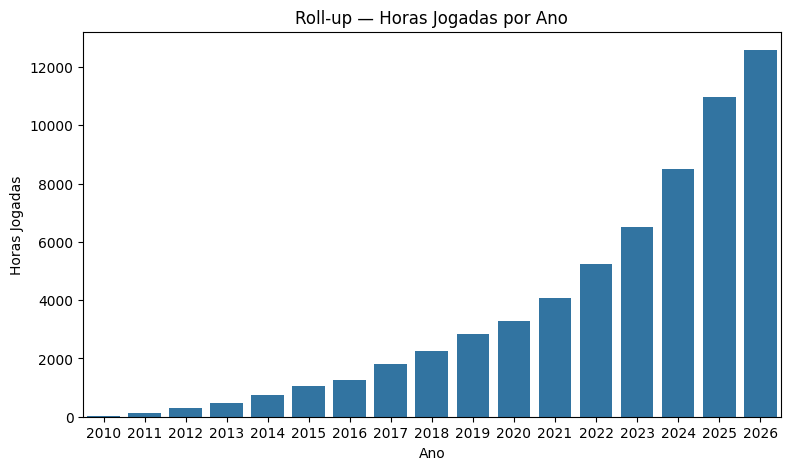

In [43]:
rollup = cubo_olap.groupby('ano').agg(
    total_sessoes=('total_sessoes', 'sum'),
    tempo_total=('tempo_total', 'sum')
).reset_index()

rollup['horas_jogadas'] = rollup['tempo_total'] / 60

display(rollup)

plt.figure(figsize=(9, 5))
sns.barplot(data=rollup, x='ano', y='horas_jogadas')
plt.title('Roll-up — Horas Jogadas por Ano')
plt.xlabel('Ano')
plt.ylabel('Horas Jogadas')
plt.show()

,ano,mes,total_sessoes,tempo_total,periodo
0,2010,4,2,161,2010-04
1,2010,6,2,269,2010-06
2,2010,7,4,147,2010-07
3,2010,8,3,341,2010-08
4,2010,9,3,417,2010-09
...,...,...,...,...,...
193,2026,6,799,78728,2026-06
194,2026,7,856,83310,2026-07
195,2026,8,889,87313,2026-08
196,2026,9,894,88446,2026-09


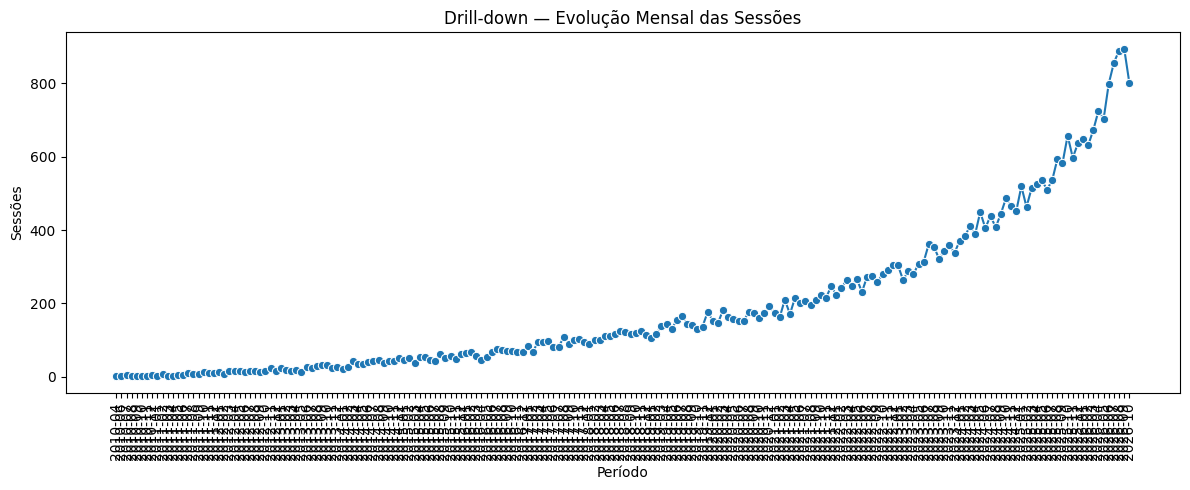

In [44]:
drilldown = cubo_olap.groupby(
    ['ano', 'mes']
).agg(
    total_sessoes=('total_sessoes', 'sum'),
    tempo_total=('tempo_total', 'sum')
).reset_index()

drilldown['periodo'] = (
    drilldown['ano'].astype(str) + '-' +
    drilldown['mes'].astype(str).str.zfill(2)
)

display(drilldown)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=drilldown,
    x='periodo',
    y='total_sessoes',
    marker='o'
)
plt.title('Drill-down — Evolução Mensal das Sessões')
plt.xlabel('Período')
plt.ylabel('Sessões')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

,genero_jogo,total_sessoes,tempo_total
0,Aventura,1182,132216
1,Ação,995,91601
2,Corrida,1028,61277
3,Esportes,861,62181
4,Estratégia,3836,422632
5,FPS,1616,111406
6,Luta,1097,57211
7,MOBA,1697,149201
8,RPG,910,136483
9,Simulação,1082,163700


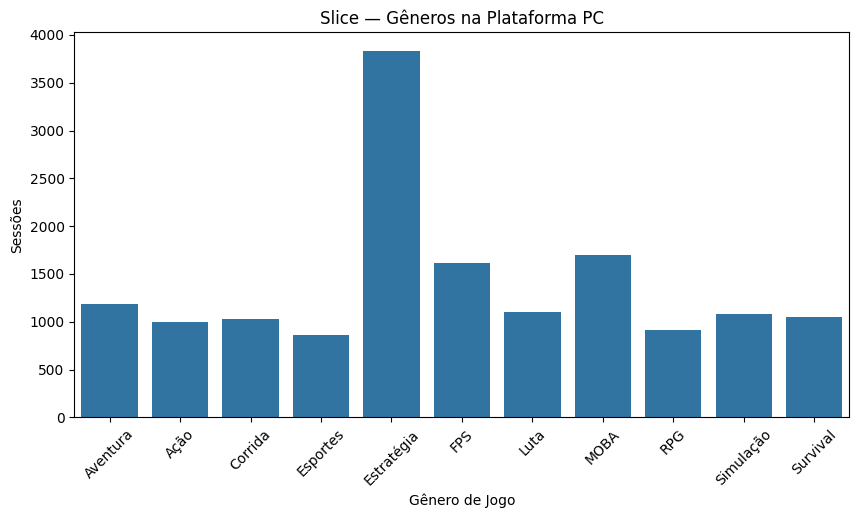

In [45]:
plataforma = cubo_olap.groupby(
    'plataforma'
)['total_sessoes'].sum().idxmax()

slice_olap = cubo_olap[
    cubo_olap['plataforma'] == plataforma
]

slice_resultado = slice_olap.groupby('genero_jogo').agg(
    total_sessoes=('total_sessoes', 'sum'),
    tempo_total=('tempo_total', 'sum')
).reset_index()

display(slice_resultado)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=slice_resultado,
    x='genero_jogo',
    y='total_sessoes'
)
plt.title(f'Slice — Gêneros na Plataforma {plataforma}')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Sessões')
plt.xticks(rotation=45)
plt.show()

,plataforma,genero_jogo,total_sessoes,tempo_total
0,PC,Corrida,215,12839
1,PC,Estratégia,838,91350
2,PC,FPS,285,20453
3,Xbox,Corrida,321,19303
4,Xbox,FPS,295,20567


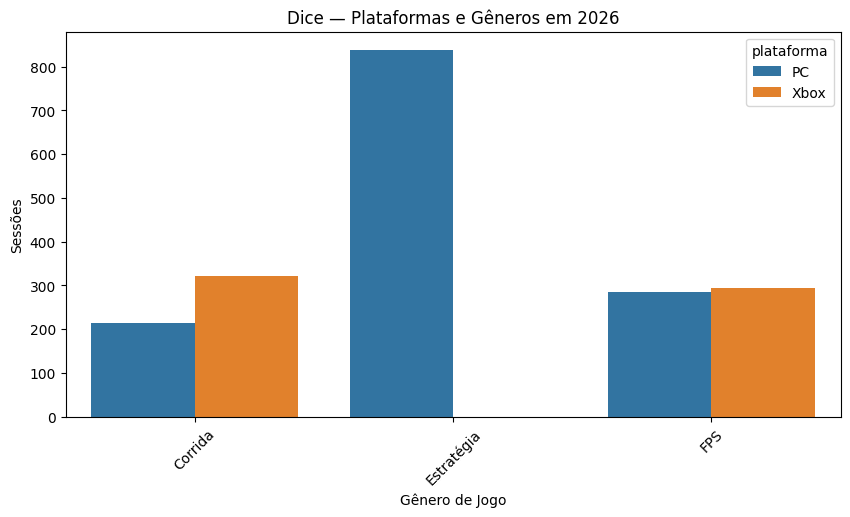

In [46]:
ano_recente = cubo_olap['ano'].max()

base_recente = cubo_olap[
    cubo_olap['ano'] == ano_recente
]

plataformas = base_recente.groupby(
    'plataforma'
)['total_sessoes'].sum().nlargest(2).index

generos = base_recente.groupby(
    'genero_jogo'
)['total_sessoes'].sum().nlargest(3).index

dice_olap = base_recente[
    base_recente['plataforma'].isin(plataformas) &
    base_recente['genero_jogo'].isin(generos)
]

dice_resultado = dice_olap.groupby(
    ['plataforma', 'genero_jogo']
).agg(
    total_sessoes=('total_sessoes', 'sum'),
    tempo_total=('tempo_total', 'sum')
).reset_index()

display(dice_resultado)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=dice_resultado,
    x='genero_jogo',
    y='total_sessoes',
    hue='plataforma'
)
plt.title(f'Dice — Plataformas e Gêneros em {ano_recente}')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Sessões')
plt.xticks(rotation=45)
plt.show()

genero_jogo,Aventura,Ação,Corrida,Esportes,Estratégia,FPS,Luta,MOBA,RPG,Simulação,Survival
plataforma,,,,,,,,,,,
Mobile,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2010.88,0.00,0.00,0.00
PC,2203.60,1526.68,1021.28,1036.35,7043.87,1856.77,953.52,2486.68,2274.72,2728.33,2932.22
PlayStation,1782.42,1765.67,1087.72,1559.28,0.00,1696.95,694.40,0.00,2496.83,2446.95,3164.07
Xbox,1857.60,1802.58,1278.95,1574.55,0.00,1692.85,1178.92,0.00,2645.10,2479.28,2788.20


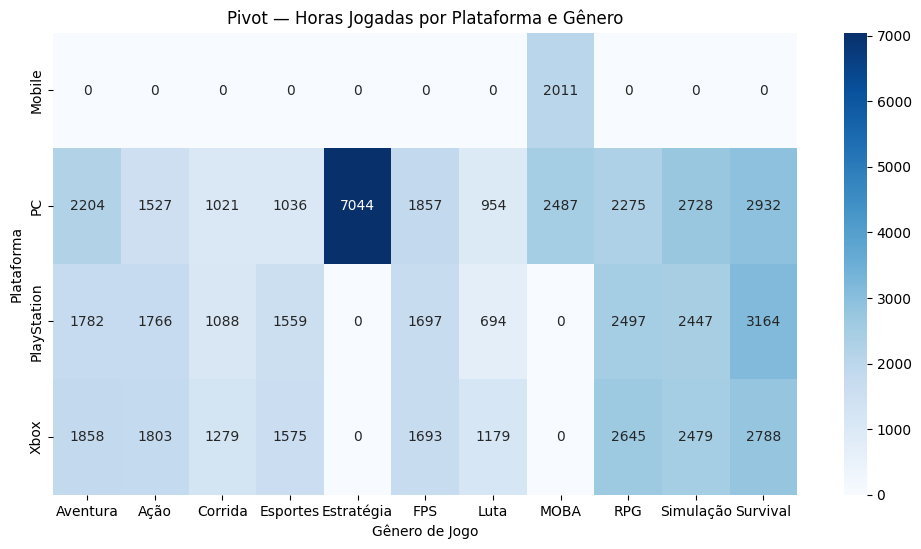

In [47]:
pivot_olap = cubo_olap.pivot_table(
    values='tempo_total',
    index='plataforma',
    columns='genero_jogo',
    aggfunc='sum',
    fill_value=0
) / 60

display(pivot_olap.round(2))

plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot_olap,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)
plt.title('Pivot — Horas Jogadas por Plataforma e Gênero')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Plataforma')
plt.show()

# Atividade dos Jogadores por Estado

A localização dos jogadores permite comparar a atividade entre diferentes regiões.

Serão analisados o número de jogadores ativos, a quantidade de sessões e o tempo total de jogo por estado.

,estado,total_sessoes,jogadores_ativos,horas_jogadas
0,ENG,1988,57,3420.87
1,BY,1133,34,2047.97
2,CL,901,24,1387.75
3,PA,759,16,1341.75
4,IDF,833,20,1333.32
...,...,...,...,...
176,DC,14,1,27.00
177,MB,23,1,26.68
178,WY,14,1,23.92
179,NLE,15,1,23.35


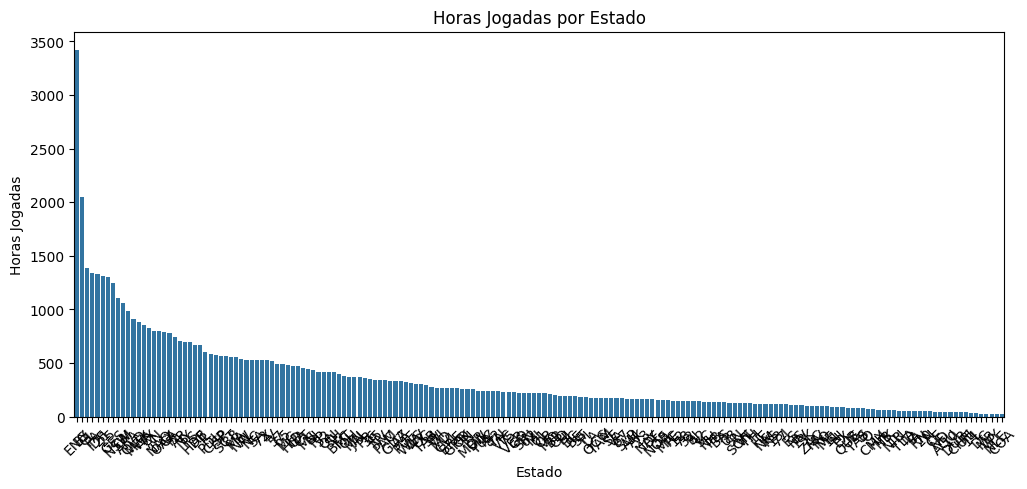

In [48]:
atividade_estado = pd.read_sql_query("""
    SELECT
        j.estado,
        COUNT(s.sessao_id) AS total_sessoes,
        COUNT(DISTINCT s.player_id) AS jogadores_ativos,
        ROUND(SUM(s.duracao_minutos) / 60.0, 2) AS horas_jogadas
    FROM sessoes s
    JOIN jogadores j
        ON s.player_id = j.player_id
    GROUP BY j.estado
    ORDER BY horas_jogadas DESC
""", conn)

display(atividade_estado)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=atividade_estado,
    x='estado',
    y='horas_jogadas'
)
plt.title('Horas Jogadas por Estado')
plt.xlabel('Estado')
plt.ylabel('Horas Jogadas')
plt.xticks(rotation=45)
plt.show()

# Evolução dos Jogadores

A evolução de nível permite observar o progresso registrado durante as sessões.

A análise compara o ganho médio de níveis entre plataformas e gêneros de jogos.

,plataforma,genero_jogo,total_sessoes,ganho_medio_nivel
0,PlayStation,Simulação,988,1.71
1,Xbox,Survival,1008,1.59
2,PC,Corrida,1028,1.52
3,PlayStation,Corrida,1110,1.47
4,PC,Esportes,861,1.43
5,PC,MOBA,1697,1.41
6,PlayStation,Luta,802,1.41
7,PlayStation,Aventura,973,1.39
8,Xbox,Luta,1326,1.37
9,Mobile,MOBA,1346,1.36


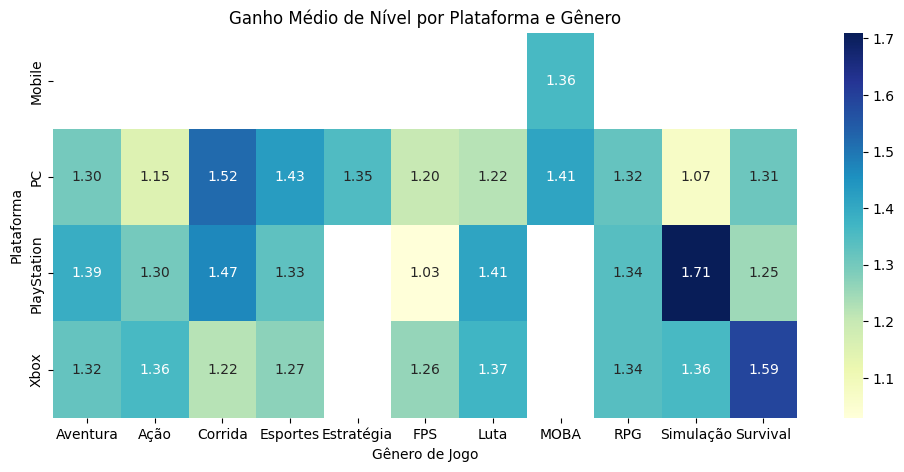

In [49]:
evolucao = pd.read_sql_query("""
    SELECT
        plataforma,
        genero_jogo,
        COUNT(sessao_id) AS total_sessoes,
        ROUND(AVG(nivel_fim - nivel_inicio), 2) AS ganho_medio_nivel
    FROM sessoes
    GROUP BY plataforma, genero_jogo
    ORDER BY ganho_medio_nivel DESC
""", conn)

display(evolucao)

matriz_evolucao = evolucao.pivot_table(
    values='ganho_medio_nivel',
    index='plataforma',
    columns='genero_jogo'
)

plt.figure(figsize=(12, 5))
sns.heatmap(
    matriz_evolucao,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)
plt.title('Ganho Médio de Nível por Plataforma e Gênero')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Plataforma')
plt.show()

# Desempenho nas Partidas

O desempenho será analisado por plataforma e gênero de jogo.

Serão utilizadas a quantidade de partidas, a pontuação média e a experiência média adquirida, permitindo identificar diferenças entre os grupos.

,plataforma,genero_jogo,total_partidas,pontuacao_media,experiencia_media
0,PlayStation,Simulação,1704,986.10,293.74
1,PlayStation,Survival,2153,996.02,293.03
2,Xbox,Survival,1880,986.40,288.45
3,PC,Simulação,1852,986.51,286.12
4,Xbox,Simulação,1673,971.42,286.02
5,PlayStation,RPG,1690,981.33,283.84
6,Xbox,RPG,1814,966.10,283.43
7,PC,Survival,2008,981.65,282.92
8,PC,RPG,1625,957.95,281.49
9,PC,Estratégia,5481,852.98,249.26


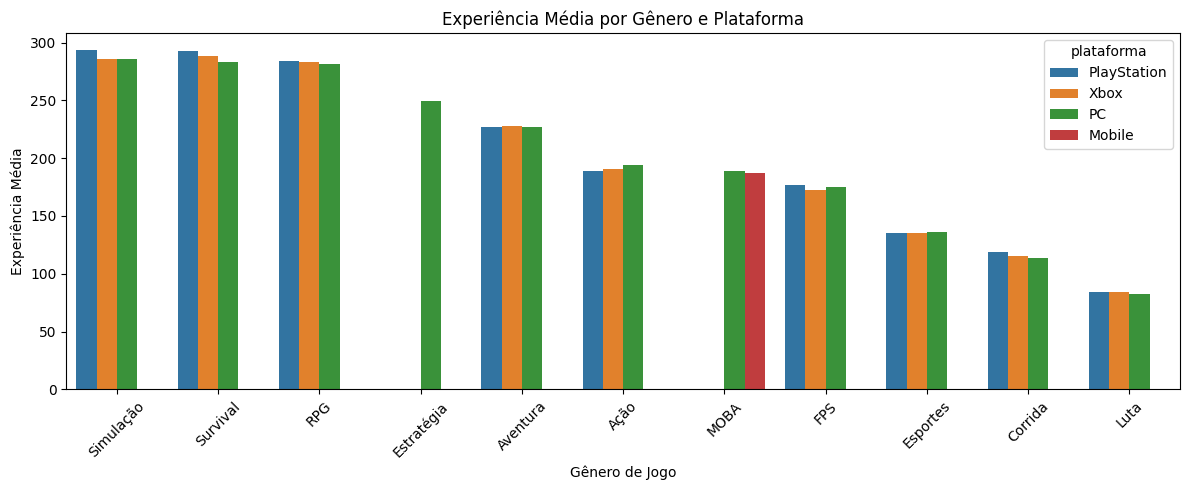

In [50]:
desempenho = pd.read_sql_query("""
    SELECT
        s.plataforma,
        s.genero_jogo,
        COUNT(p.partida_id) AS total_partidas,
        ROUND(AVG(p.pontuacao), 2) AS pontuacao_media,
        ROUND(AVG(p.experiencia_ganha), 2) AS experiencia_media
    FROM partidas p
    JOIN sessoes s
        ON p.sessao_id = s.sessao_id
    GROUP BY s.plataforma, s.genero_jogo
    ORDER BY experiencia_media DESC
""", conn)

display(desempenho)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=desempenho,
    x='genero_jogo',
    y='experiencia_media',
    hue='plataforma'
)
plt.title('Experiência Média por Gênero e Plataforma')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Experiência Média')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Resultados das Partidas

A distribuição dos resultados permite comparar o desempenho registrado nas partidas.

A análise apresenta a quantidade de partidas por resultado e gênero de jogo.

,genero_jogo,resultado,total_partidas
0,Aventura,Derrota,2239
1,Aventura,Vitória,2237
2,Aventura,Empate,260
3,Ação,Vitória,2304
4,Ação,Derrota,2295
5,Ação,Empate,287
6,Corrida,Vitória,2611
7,Corrida,Derrota,2611
8,Corrida,Empate,322
9,Esportes,Vitória,2537


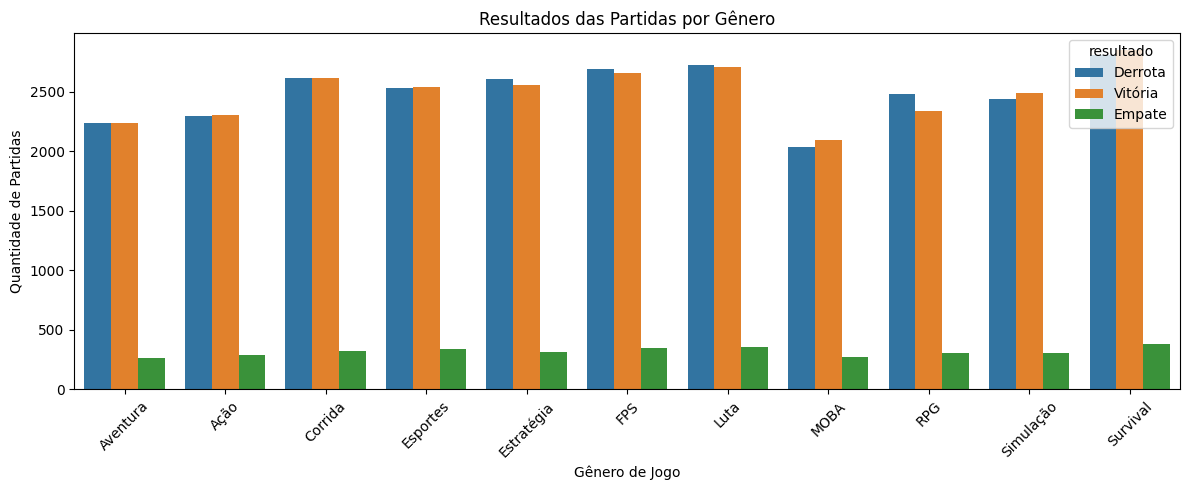

In [51]:
resultados_partidas = pd.read_sql_query("""
    SELECT
        s.genero_jogo,
        p.resultado,
        COUNT(p.partida_id) AS total_partidas
    FROM partidas p
    JOIN sessoes s
        ON p.sessao_id = s.sessao_id
    GROUP BY s.genero_jogo, p.resultado
    ORDER BY s.genero_jogo, total_partidas DESC
""", conn)

display(resultados_partidas)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=resultados_partidas,
    x='genero_jogo',
    y='total_partidas',
    hue='resultado'
)
plt.title('Resultados das Partidas por Gênero')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Quantidade de Partidas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Análise de Compras

As compras permitem avaliar o comportamento de consumo dos jogadores.

Serão analisados o valor total comercializado, a quantidade vendida e a participação de cada categoria de item.

,categoria_item,quantidade_vendida,valor_total
0,Moeda virtual,274,6836.07
1,Skin,409,6026.32
2,Personagem,196,5930.32
3,Cosmético,236,4917.98
4,Passe de batalha,160,4307.51
5,Boost,183,4216.22
6,DLC,187,3754.80
7,Emote,161,2675.98
8,Pacote,172,2642.29
9,Acessório,239,1446.30


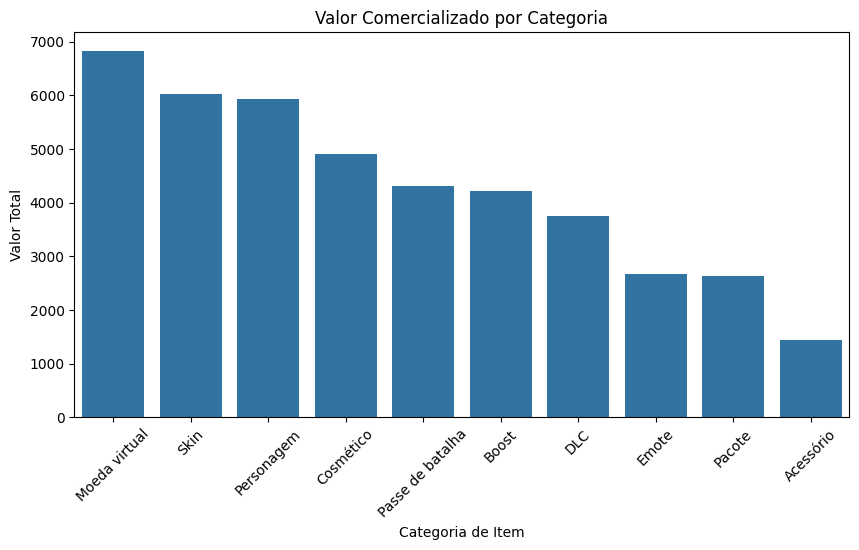

In [52]:
faturamento = pd.read_sql_query("""
    SELECT
        i.categoria_item,
        SUM(ic.quantidade) AS quantidade_vendida,
        ROUND(SUM(ic.valor_total_item), 2) AS valor_total
    FROM itens_compras ic
    JOIN itens i
        ON ic.item_id = i.item_id
    GROUP BY i.categoria_item
    ORDER BY valor_total DESC
""", conn)

display(faturamento)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=faturamento,
    x='categoria_item',
    y='valor_total'
)
plt.title('Valor Comercializado por Categoria')
plt.xlabel('Categoria de Item')
plt.ylabel('Valor Total')
plt.xticks(rotation=45)
plt.show()

,nome_item,categoria_item,quantidade_vendida,valor_total
0,Skin Glacial,Skin,90,432.16
1,Skin Tempestade,Skin,76,1475.63
2,2500 Moedas,Moeda virtual,76,2952.57
3,Boost de XP,Boost,75,2206.60
4,1000 Moedas,Moeda virtual,70,328.04
5,Expansão Sombria,DLC,69,328.27
6,Skin Dragão,Skin,68,327.32
7,500 Moedas,Moeda virtual,68,658.80
8,Roupa Especial,Cosmético,68,325.37
9,Pacote Inicial,Pacote,68,657.82


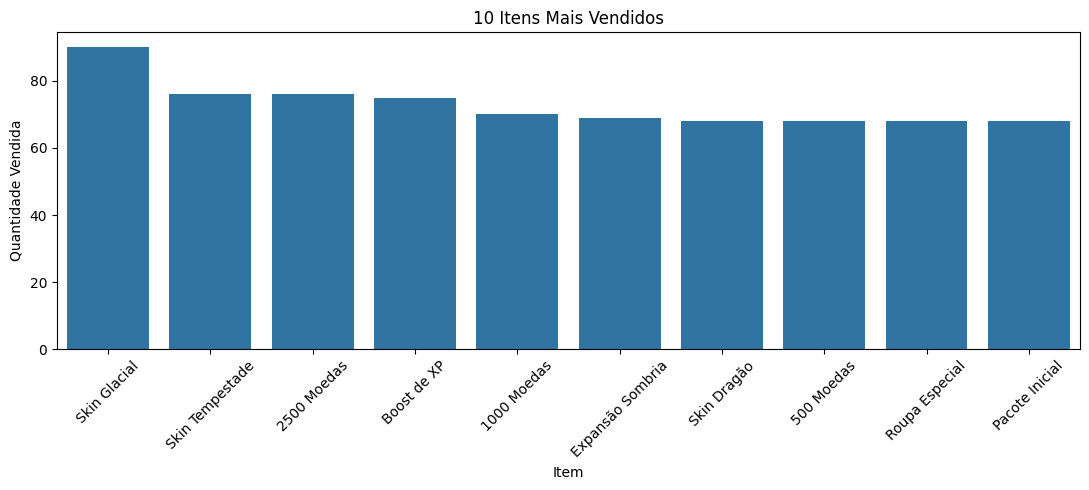

In [53]:
itens_vendidos = pd.read_sql_query("""
    SELECT
        i.nome_item,
        i.categoria_item,
        SUM(ic.quantidade) AS quantidade_vendida,
        ROUND(SUM(ic.valor_total_item), 2) AS valor_total
    FROM itens_compras ic
    JOIN itens i
        ON ic.item_id = i.item_id
    GROUP BY i.item_id, i.nome_item, i.categoria_item
    ORDER BY quantidade_vendida DESC
    LIMIT 10
""", conn)

display(itens_vendidos)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=itens_vendidos,
    x='nome_item',
    y='quantidade_vendida'
)
plt.title('10 Itens Mais Vendidos')
plt.xlabel('Item')
plt.ylabel('Quantidade Vendida')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Consumo por Plataforma e Gênero

Esta análise relaciona as compras às sessões em que foram realizadas.

O objetivo é identificar quais plataformas e gêneros de jogos apresentam maior valor comercializado e maior quantidade de compras.

,plataforma,genero_jogo,total_compras,valor_total
0,PC,Estratégia,136,4317.07
1,PC,Survival,58,2056.53
2,PlayStation,Ação,59,1954.56
3,Xbox,RPG,68,1926.63
4,Xbox,Esportes,56,1872.18
5,Xbox,FPS,54,1723.85
6,Xbox,Ação,62,1672.23
7,PC,MOBA,53,1663.44
8,PC,Luta,63,1514.02
9,PC,Simulação,47,1498.05


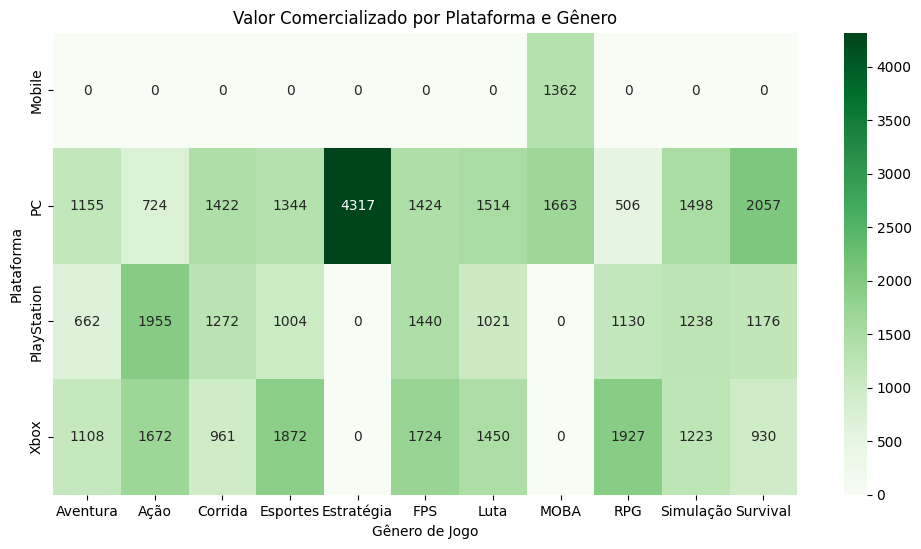

In [54]:
consumo = pd.read_sql_query("""
    SELECT
        s.plataforma,
        s.genero_jogo,
        COUNT(DISTINCT c.compra_id) AS total_compras,
        ROUND(SUM(ic.valor_total_item), 2) AS valor_total
    FROM compras c
    JOIN sessoes s
        ON c.sessao_id = s.sessao_id
    JOIN itens_compras ic
        ON c.compra_id = ic.compra_id
    GROUP BY s.plataforma, s.genero_jogo
    ORDER BY valor_total DESC
""", conn)

display(consumo)

matriz_consumo = consumo.pivot_table(
    values='valor_total',
    index='plataforma',
    columns='genero_jogo',
    aggfunc='sum',
    fill_value=0
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    matriz_consumo,
    annot=True,
    fmt='.0f',
    cmap='Greens'
)
plt.title('Valor Comercializado por Plataforma e Gênero')
plt.xlabel('Gênero de Jogo')
plt.ylabel('Plataforma')
plt.show()

# Engajamento e Consumo dos Jogadores

Esta análise investiga a relação entre o tempo total de jogo e o valor gasto pelos jogadores.

A comparação pode ajudar a identificar padrões de consumo associados à atividade dos usuários.

A existência de uma relação entre essas variáveis não significa necessariamente que uma cause a outra.

In [55]:
atividade_jogadores = sessoes.groupby('player_id').agg(
    total_sessoes=('sessao_id', 'count'),
    tempo_total=('duracao_minutos', 'sum')
).reset_index()

compras_jogadores = compras.merge(
    sessoes[['sessao_id', 'player_id']],
    on='sessao_id',
    how='inner'
)

valores_compras = itens_compras.groupby('compra_id').agg(
    valor_compra=('valor_total_item', 'sum')
).reset_index()

compras_jogadores = compras_jogadores.merge(
    valores_compras,
    on='compra_id',
    how='inner'
)

gastos_jogadores = compras_jogadores.groupby('player_id').agg(
    valor_gasto=('valor_compra', 'sum')
).reset_index()

engajamento_consumo = atividade_jogadores.merge(
    gastos_jogadores,
    on='player_id',
    how='left'
)

engajamento_consumo['valor_gasto'] = (
    engajamento_consumo['valor_gasto'].fillna(0)
)

engajamento_consumo['horas_jogadas'] = (
    engajamento_consumo['tempo_total'] / 60
)

display(engajamento_consumo.head(10))

fig = px.scatter(
    engajamento_consumo,
    x='horas_jogadas',
    y='valor_gasto',
    hover_data=['player_id', 'total_sessoes'],
    title='Relação entre Tempo de Jogo e Valor Gasto',
    labels={
        'horas_jogadas': 'Horas Jogadas',
        'valor_gasto': 'Valor Gasto'
    }
)

fig.show()

,player_id,total_sessoes,tempo_total,valor_gasto,horas_jogadas
0,1,14,1946,143.61,32.433333
1,2,19,1326,0.00,22.100000
2,3,22,2750,0.00,45.833333
3,4,64,4494,0.00,74.900000
4,5,61,8358,413.14,139.300000
5,6,10,1300,0.00,21.666667
6,7,20,1255,0.00,20.916667
7,8,28,3661,19.80,61.016667
8,9,52,5441,0.00,90.683333
9,10,32,3703,0.00,61.716667


# Indicadores Gerais

Os indicadores gerais permitem resumir os principais resultados da base analisada.

Serão apresentados o total de jogadores, sessões, partidas, compras, horas jogadas e valor comercializado.

In [56]:
indicadores = pd.DataFrame({
    'Indicador': [
        'Jogadores cadastrados',
        'Jogadores ativos',
        'Sessões registradas',
        'Partidas registradas',
        'Compras registradas',
        'Horas jogadas',
        'Valor comercializado'
    ],
    'Valor': [
        jogadores['player_id'].nunique(),
        sessoes['player_id'].nunique(),
        sessoes['sessao_id'].nunique(),
        partidas['partida_id'].nunique(),
        compras['compra_id'].nunique(),
        round(sessoes['duracao_minutos'].sum() / 60, 2),
        round(itens_compras['valor_total_item'].sum(), 2)
    ]
})

display(indicadores)

,Indicador,Valor
0,Jogadores cadastrados,1000.00
1,Jogadores ativos,1000.00
2,Sessões registradas,37366.00
3,Partidas registradas,58312.00
4,Compras registradas,1425.00
5,Horas jogadas,62067.22
6,Valor comercializado,42753.79
